In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
df = pd.read_excel('dataset/kerala_land_price_dataset.xlsx')

In [4]:
df.shape

(119, 11)

In [5]:
df.head()


,Year,District,Place,Land_Type,Road_Access,Distance_Town_km,Distance_Highway_m,Area_Cent,Land_Price_Per_Cent_INR,Source,Data_Status
0,2010,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.0,500,1,350000,NaN,Actual price required
1,2011,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.5,530,1,457000,NaN,Actual price required
2,2012,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,2.0,532,1,525000,NaN,Actual price required
3,2013,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.0,534,1,600000,NaN,Actual price required
4,2014,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.0,536,1,776000,NaN,Actual price required


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Year                     119 non-null    int64  
 1   District                 119 non-null    object 
 2   Place                    119 non-null    object 
 3   Land_Type                119 non-null    object 
 4   Road_Access              119 non-null    object 
 5   Distance_Town_km         119 non-null    float64
 6   Distance_Highway_m       119 non-null    int64  
 7   Area_Cent                119 non-null    int64  
 8   Land_Price_Per_Cent_INR  119 non-null    int64  
 9   Source                   0 non-null      float64
 10  Data_Status              119 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 10.4+ KB


In [7]:
path = 'dataset/land_price_processed.csv'

if os.path.exists(path):
    # normal route: file created by the preprocessing notebook
    df = pd.read_csv(path)
    print('Loaded', path)
else:
    # fallback: build the same processed data here from the raw Excel file
    print(path, 'not found - rebuilding from the raw Excel file')
    df = pd.read_excel('dataset/kerala_land_price_dataset.xlsx')
    df['Place'] = df['Place'].str.strip()
    df['Land_Type'] = df['Land_Type'].str.strip().str.replace('Forntage', 'Frontage')
    df = df.drop(columns=['District', 'Road_Access', 'Area_Cent', 'Source', 'Data_Status'])
    df = df.rename(columns={'Land_Price_Per_Cent_INR': 'Price'})
    df = df.sort_values(['Place', 'Year']).reset_index(drop=True)
    df['t'] = df['Year'] - 2010
    df['log_price'] = np.log(df['Price'])
    df['YoY_%'] = df.groupby('Place')['Price'].pct_change() * 100

print(df.columns.tolist())

Loaded dataset/land_price_processed.csv
['Year', 'Place', 'Land_Type', 'Distance_Town_km', 'Distance_Highway_m', 'Price', 't', 'log_price', 'YoY_%']


In [8]:
df.head()

,Year,Place,Land_Type,Distance_Town_km,Distance_Highway_m,Price,t,log_price,YoY_%
0,2010,Akkulam,NH 66 Bypass Frontage,1.0,300,350000,0,12.765688,NaN
1,2011,Akkulam,NH 66 Bypass Frontage,1.0,320,420000,1,12.948010,20.000000
2,2012,Akkulam,NH 66 Bypass Frontage,1.0,300,550000,2,13.217674,30.952381
3,2013,Akkulam,NH 66 Bypass Frontage,1.0,300,600000,3,13.304685,9.090909
4,2014,Akkulam,NH 66 Bypass Frontage,1.0,300,750000,4,13.527828,25.000000


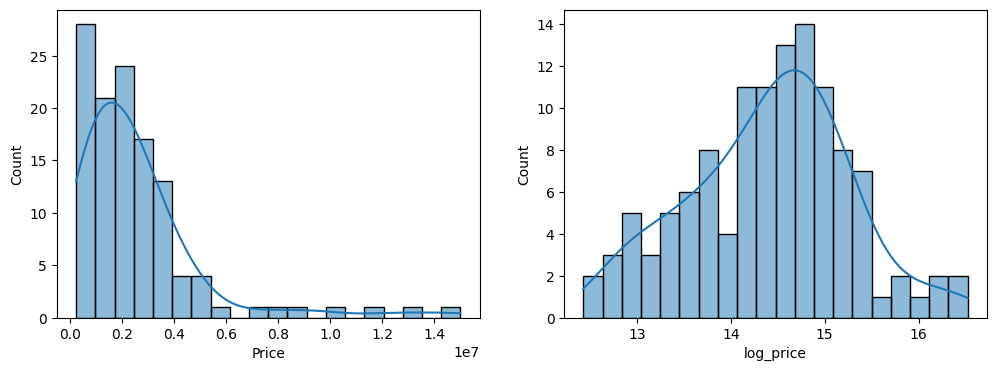

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Price'], bins=20, kde=True, ax=axes[0])
sns.histplot(df['log_price'], bins=20, kde=True, ax=axes[1])
plt.show()

### 5.2 Price trend per place

In [10]:
pivot = df.pivot(index='Year', columns='Place', values='Price')

In [11]:
pivot.head()

Place,Akkulam,East Fort,Karyavattom,Kavadior,Kazhakkoottam,Pattom,Vizhinjam
Year,,,,,,,
2010,350000,1000000,250000,350000,350000,1200000,400000
2011,420000,1400000,300000,400000,457000,1300000,500000
2012,550000,1800000,400000,600000,525000,1455000,600000
2013,600000,2000000,600000,800000,600000,1800000,700000
2014,750000,2500000,900000,1000000,776000,1978000,800000


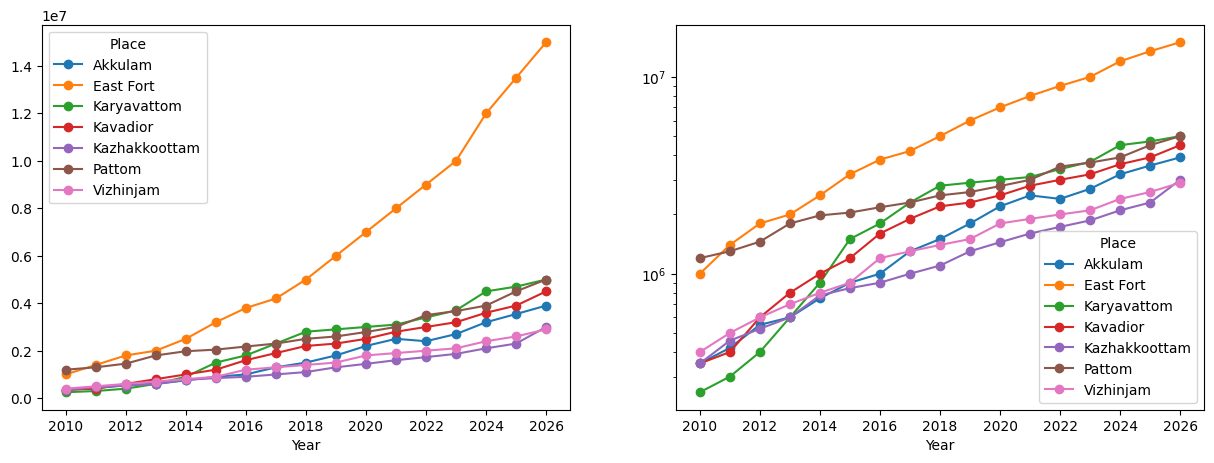

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
pivot.plot(ax=axes[0], marker='o')
pivot.plot(ax=axes[1], marker='o', logy=True)
plt.show()

### 5.3 Price by place (boxplot)

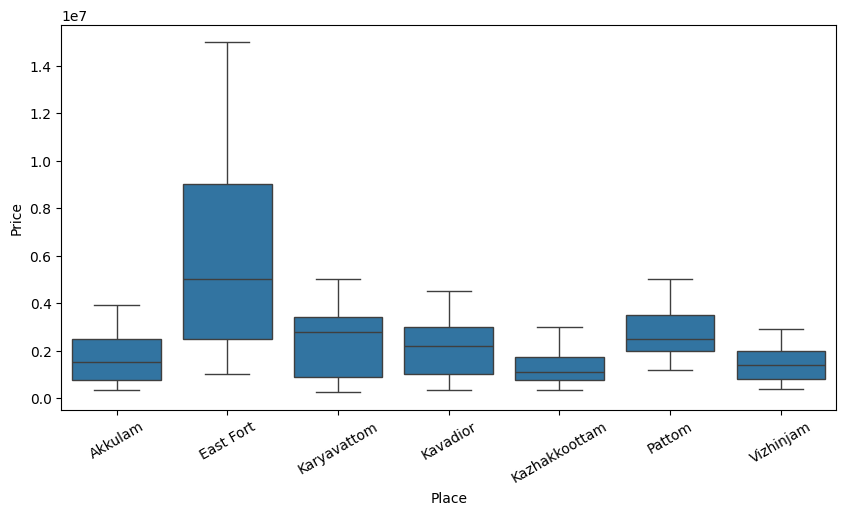

In [13]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Place', y='Price')
plt.xticks(rotation=30)
plt.show()

In [14]:
df.groupby('Place')['Price'].describe()

,count,mean,std,min,25%,50%,75%,max
Place,,,,,,,,
Akkulam,17.0,1.742059e+06,1.147820e+06,350000.0,750000.0,1500000.0,2500000.0,3900000.0
East Fort,17.0,6.200000e+06,4.412624e+06,1000000.0,2500000.0,5000000.0,9000000.0,15000000.0
Karyavattom,17.0,2.420588e+06,1.583219e+06,250000.0,900000.0,2800000.0,3400000.0,5000000.0
Kavadior,17.0,2.108824e+06,1.278944e+06,350000.0,1000000.0,2200000.0,3000000.0,4500000.0
Kazhakkoottam,17.0,1.287882e+06,7.339601e+05,350000.0,776000.0,1100000.0,1730000.0,3000000.0
Pattom,17.0,2.688941e+06,1.108250e+06,1200000.0,1978000.0,2500000.0,3500000.0,5000000.0
Vizhinjam,17.0,1.470588e+06,7.695491e+05,400000.0,800000.0,1400000.0,2000000.0,2900000.0


### 5.4 YoY growth heatmap

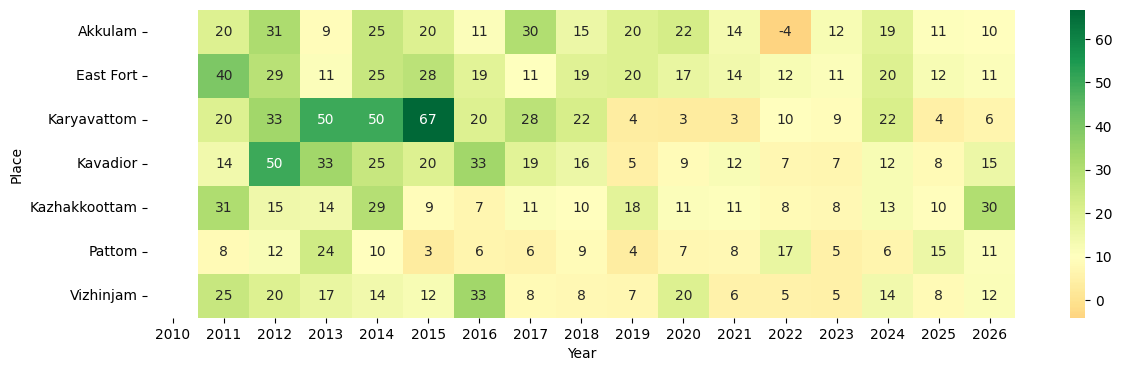

In [15]:
yoy = df.pivot(index='Place', columns='Year', values='YoY_%')
plt.figure(figsize=(14, 4))
sns.heatmap(yoy, annot=True, fmt='.0f', cmap='RdYlGn', center=10)
plt.show()

### 5.5 Land type comparison

In [16]:
df.groupby('Land_Type')['Price'].mean()

Land_Type
NH 66 Bypass Frontage             1.514971e+06
NH HIGHWAY Frontage               1.470588e+06
Prime / Main Road / Commercial    3.354588e+06
Name: Price, dtype: float64

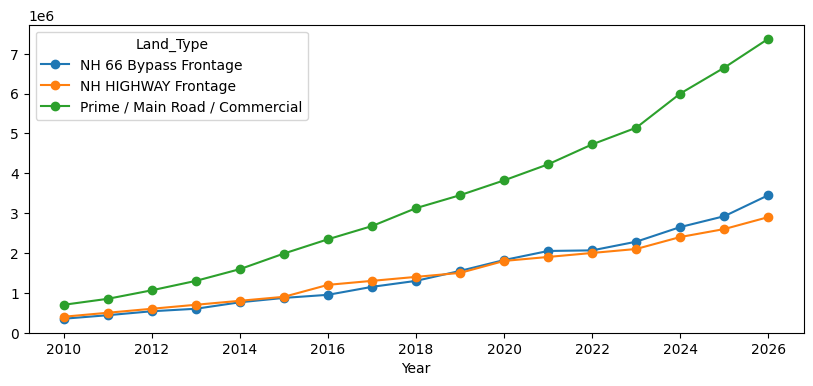

In [17]:
df.groupby(['Year', 'Land_Type'])['Price'].mean().unstack().plot(figsize=(10, 4), marker='o')
plt.show()

### 5.6 Correlation

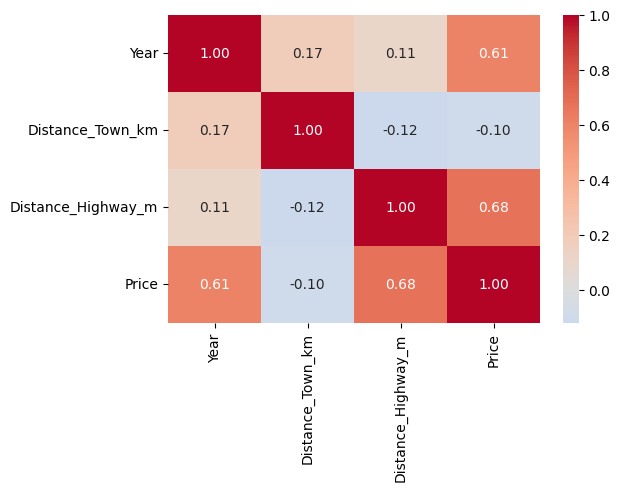

In [18]:
plt.figure(figsize=(6, 4))
sns.heatmap(df[['Year', 'Distance_Town_km', 'Distance_Highway_m', 'Price']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

### 5.7 CAGR (Compound Annual Growth Rate)
##### Formula: `(last / first) ^ (1 / years) − 1)

In [19]:
first = pivot.iloc[0]
last = pivot.iloc[-1]
cagr = ((last / first) ** (1 / 16) - 1) * 100
cagr.sort_values(ascending=False)

Place
Karyavattom      20.590855
East Fort        18.441992
Kavadior         17.306352
Akkulam          16.261865
Kazhakkoottam    14.370976
Vizhinjam        13.180374
Pattom            9.329358
dtype: float64